In [1]:

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("Python version:", sys.version.split()[0])
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpus))

if gpus:
    print("GPU device:", gpus[0].name)
else:
    print("Using CPU for now.")

print("\nStep 1 completed successfully!")


Python version: 3.13.18
TensorFlow version: 2.21.0
NumPy version: 2.1.3
GPU available: False
Using CPU for now.

Step 1 completed successfully!


In [2]:

import os

# Create a folder for the dataset
DATA_DIR = "/content/brain_tumor_data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset folder created:", DATA_DIR)
print("Folder exists:", os.path.isdir(DATA_DIR))


Dataset folder created: /content/brain_tumor_data
Folder exists: True


In [3]:

!pip -q install kaggle
print("Kaggle installed successfully!")


Kaggle installed successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [5]:

import os
from google.colab import userdata

# Read the Kaggle API token securely from Colab Secrets
kaggle_token = userdata.get("KAGGLE_API_TOKEN")

# Set the token for the Kaggle API
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

print("Kaggle token configured successfully!")


Kaggle token configured successfully!


In [6]:

import os
import subprocess
import zipfile

# Dataset download location
DATA_DIR = "/content/brain_tumor_data"
os.makedirs(DATA_DIR, exist_ok=True)

# Download the dataset using your Colab secret
env = os.environ.copy()
env["KAGGLE_API_TOKEN"] = kaggle_token

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", "masoudnickparvar/brain-tumor-mri-dataset",
        "-p", DATA_DIR
    ],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("Download failed:")
    print(result.stderr)
else:
    zip_files = [
        f for f in os.listdir(DATA_DIR)
        if f.lower().endswith(".zip")
    ]

    if not zip_files:
        print("Download completed, but no ZIP file was found.")
    else:
        zip_path = os.path.join(DATA_DIR, zip_files[0])

        print("Extracting dataset...")
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(DATA_DIR)

        print("Dataset downloaded and extracted successfully!")
        print("Location:", DATA_DIR)
        print("Top-level items:", os.listdir(DATA_DIR)[:15])


Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)


Extracting dataset...
Dataset downloaded and extracted successfully!
Location: /content/brain_tumor_data
Top-level items: ['Training', 'brain-tumor-mri-dataset.zip', 'Testing']


In [7]:

import os

DATA_DIR = "/content/brain_tumor_data"

print("Dataset directory exists:", os.path.isdir(DATA_DIR))
print("\nFolders and files found:")

for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)

    # Show only the first two folder levels
    if level <= 2:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for filename in files[:5]:
            print(f"{indent}    {filename}")

    # Avoid printing every image filename
    if level >= 2:
        dirs[:] = []


Dataset directory exists: True

Folders and files found:
brain_tumor_data/
    brain-tumor-mri-dataset.zip
    Training/
        meningioma/
            Tr-me_220.jpg
            Tr-me_1192.jpg
            Tr-me_1162.jpg
            Tr-me_1007.jpg
            Tr-me_343.jpg
        glioma/
            Tr-gl_1247.jpg
            Tr-gl_904.jpg
            Tr-gl_951.jpg
            Tr-gl_1316.jpg
            Tr-gl_1210.jpg
        pituitary/
            Tr-pi_1319.jpg
            Tr-pi_200.jpg
            Tr-pi_1354.jpg
            Tr-pi_587.jpg
            Tr-pi_1079.jpg
        notumor/
            Tr-no_1089.jpg
            Tr-no_941.jpg
            Tr-no_904.jpg
            Tr-no_1383.jpg
            Tr-no_328.jpg
    Testing/
        meningioma/
            Te-aug-me_71.jpg
            Te-me_128.jpg
            Te-me_240.jpg
            Te-me_178.jpg
            Te-me_15.jpg
        glioma/
            Te-gl_174.jpg
            Te-gl_284.jpg
            Te-gl_159.jpg
            Te-gl

In [8]:

import os

DATA_DIR = "/content/brain_tumor_data"
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

classes = ["glioma", "meningioma", "notumor", "pituitary"]

print("TRAINING DATASET")
print("-" * 35)

for class_name in classes:
    folder = os.path.join(TRAIN_DIR, class_name)
    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    print(f"{class_name}: {count} images")

print("\nTESTING DATASET")
print("-" * 35)

for class_name in classes:
    folder = os.path.join(TEST_DIR, class_name)
    count = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])
    print(f"{class_name}: {count} images")

print("\nDataset verification completed!")


TRAINING DATASET
-----------------------------------
glioma: 1400 images
meningioma: 1400 images
notumor: 1400 images
pituitary: 1400 images

TESTING DATASET
-----------------------------------
glioma: 400 images
meningioma: 400 images
notumor: 400 images
pituitary: 400 images

Dataset verification completed!


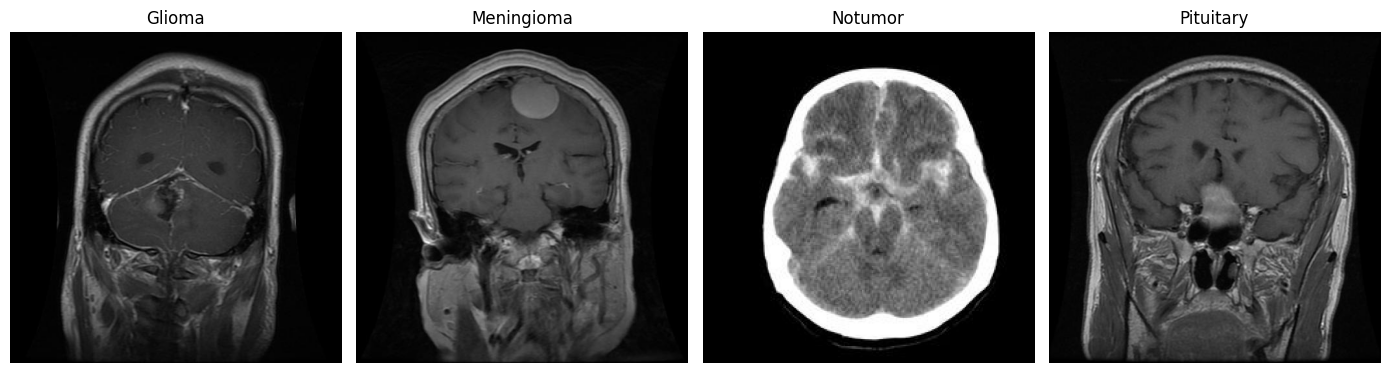

Sample MRI images displayed successfully!


In [9]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/content/brain_tumor_data"
TRAIN_DIR = os.path.join(DATA_DIR, "Training")

classes = ["glioma", "meningioma", "notumor", "pituitary"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, class_name in zip(axes, classes):
    class_dir = os.path.join(TRAIN_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    image_path = os.path.join(class_dir, random.choice(image_files))

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name.capitalize())
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Sample MRI images displayed successfully!")


In [10]:

import os
import tensorflow as tf

# Dataset paths
DATA_DIR = "/content/brain_tumor_data"
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

# Image and training settings
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load testing images
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Normalize pixel values to 0–1
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    lambda images, labels: (normalization_layer(images), labels),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Optimize input pipeline
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("\nClass names:", train_ds.class_names if hasattr(train_ds, "class_names") else ["glioma", "meningioma", "notumor", "pituitary"])
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Dataset loading and normalization completed!")


Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Image size: (128, 128)
Batch size: 32
Dataset loading and normalization completed!


In [11]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Build a CNN from scratch
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(4, activation="softmax")
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
model.summary()

print("\nCNN model created and compiled successfully!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,486,212 (9.48 MB)

 Trainable params: 2,486,212 (9.48 MB)

 Non-trainable params: 0 (0.00 B)


CNN model created and compiled successfully!


In [12]:

# Train the CNN model
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    verbose=1
)

print("\nCNN training completed!")


Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.6370 - loss: 0.8460 - val_accuracy: 0.7081 - val_loss: 0.9954
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 268s 2s/step - accuracy: 0.8036 - loss: 0.4975 - val_accuracy: 0.7619 - val_loss: 1.0388
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 319s 2s/step - accuracy: 0.8552 - loss: 0.3827 - val_accuracy: 0.8313 - val_loss: 0.7051
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 325s 2s/step - accuracy: 0.8866 - loss: 0.2909 - val_accuracy: 0.8238 - val_loss: 0.9089
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 323s 2s/step - accuracy: 0.9079 - loss: 0.2422 - val_accuracy: 0.8144 - val_loss: 0.8977
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 291s 2s/step - accuracy: 0.9250 - loss: 0.2025 - val_accuracy: 0.8719 - val_loss: 0.7129
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.9371 - loss: 0.1538 - val_accuracy: 0.8769 - val_loss: 0.7463
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 316s 2s/step - accuracy: 0.9579 - loss: 0.1129 - val_accu

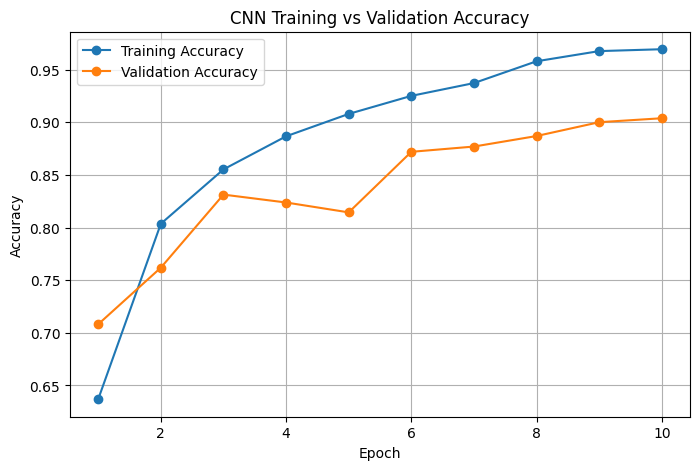

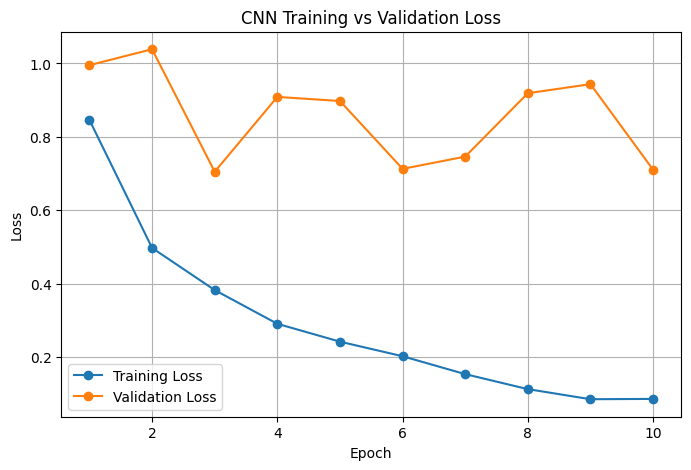

Training curves plotted successfully!


In [13]:

import matplotlib.pyplot as plt

# Get training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o", label="Validation Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")
plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

print("Training curves plotted successfully!")


50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 455ms/step

Test accuracy: 0.9038 (90.38%)

Classification Report:

              precision    recall  f1-score   support

      glioma     0.8870    0.7850    0.8329       400
  meningioma     0.8793    0.8925    0.8859       400
     notumor     0.9053    0.9800    0.9412       400
   pituitary     0.9410    0.9575    0.9492       400

    accuracy                         0.9038      1600
   macro avg     0.9032    0.9037    0.9023      1600
weighted avg     0.9032    0.9038    0.9023      1600



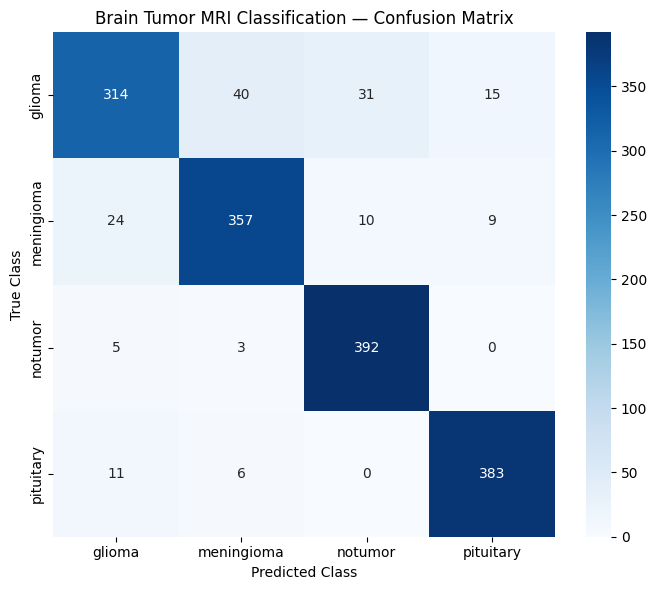

In [14]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Collect true labels and model predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Class names in the dataset's directory order
class_names = ["glioma", "meningioma", "notumor", "pituitary"]

# Calculate overall accuracy
test_accuracy = accuracy_score(y_true, y_pred)
print(f"\nTest accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

# Detailed classification report
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Brain Tumor MRI Classification — Confusion Matrix")
plt.tight_layout()
plt.show()


In [15]:

import os

MODEL_PATH = "/content/brain_tumor_cnn.keras"

# Save the trained model
model.save(MODEL_PATH)

print("Model saved successfully!")
print("Saved location:", MODEL_PATH)
print("File size: {:.2f} MB".format(
    os.path.getsize(MODEL_PATH) / (1024 * 1024)
))


Model saved successfully!
Saved location: /content/brain_tumor_cnn.keras
File size: 28.50 MB


In [16]:

from google.colab import files
import os

MODEL_PATH = "/content/brain_tumor_cnn.keras"

if os.path.exists(MODEL_PATH):
    files.download(MODEL_PATH)
    print("Model download started!")
else:
    print("Model file not found. Please run Step 12 first.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model download started!
